# 06 · From Scores to a Call Policy
### IT3091 Machine Learning · Group 2026-AI-42 · Evaluation, recommendation & documentation lead

Translating model prediction scores into actionable call center targeting policies under non-stationary conditions.

- **Input:** Tuned pipeline (notebook 04)
- **Output:** `artifacts/policy_scores.npz`, `reports/tables/policy_comparison.csv`, `reports/tables/test_blocks.csv`

1. **Temporal stability analysis:** Evaluating ranking consistency across consecutive time blocks.
2. **Calibration & ranking:** Applying rolling intercept recalibration to track changing base rates without altering client rank order.
3. **Policy optimization:** Comparing capacity-constrained (top-k) and profit-maximizing thresholds against baseline strategies.

> Note: Cost and revenue parameters (`CALL_BUDGET`, `COST_PER_CALL`, `VALUE_PER_SUBSCRIPTION`) are baseline values used to demonstrate the decision framework.

In [1]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import json, joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from scipy.optimize import brentq
from scipy.special import expit, logit
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve

from src.config import *
from src.data.prepare import load_modelling_data
from src.evaluation.metrics import decile_table, rank_order, topk_metrics
from src.plotting import set_style, save_fig

set_style()
pd.set_option("display.max_columns", 60, "display.width", 170)
data = load_modelling_data()
X_train, y_train, X_pilot, y_pilot, X_test, y_test = (data[k] for k in ["X_train", "y_train", "X_pilot", "y_pilot", "X_test", "y_test"])
best_pipe = joblib.load(ARTIFACTS_DIR / "tuned_pipeline.joblib")
TUNED_NAME = json.loads((ARTIFACTS_DIR / "tuned_params.json").read_text())["name"]
test_scores = dict(np.load(ARTIFACTS_DIR / "test_scores.npz"))
s_raw = test_scores[TUNED_NAME]
BLOCK = PILOT_ROWS

Loading local file: bank-additional-full.csv
Rows: raw 41,188 -> cleaned 41,176 | train 32,940 (rate 6.38%) | pilot 500 | test 7,736 (rate 32.41%)


---
## 1 · Temporal ranking stability and within-block performance

Evaluating ranking stability across time blocks (500 contacts each) to isolate client discrimination skill from macroscopic base rate shifts.

Trained on first 75% of training -> AUC on the NEXT training block: 0.626 | on the test period: 0.637
Trained on ALL training rows      -> AUC on the test period       : 0.689


block,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
base_rate,0.084,0.092,0.08,0.108,0.130,0.258,0.384,0.348,0.336,0.404,0.468,0.540,0.524,0.564,0.462
auc,0.668,0.544,0.62,0.533,0.525,0.596,0.594,0.587,0.605,0.551,0.581,0.645,0.710,0.719,0.656
lift_at_budget,1.548,1.196,2.00,0.833,1.154,1.434,1.458,1.408,1.518,1.262,1.047,1.463,1.431,1.418,1.082


Global test ROC-AUC 0.689 | mean WITHIN-block ROC-AUC 0.609 | mean within-block lift@20% 1.35x


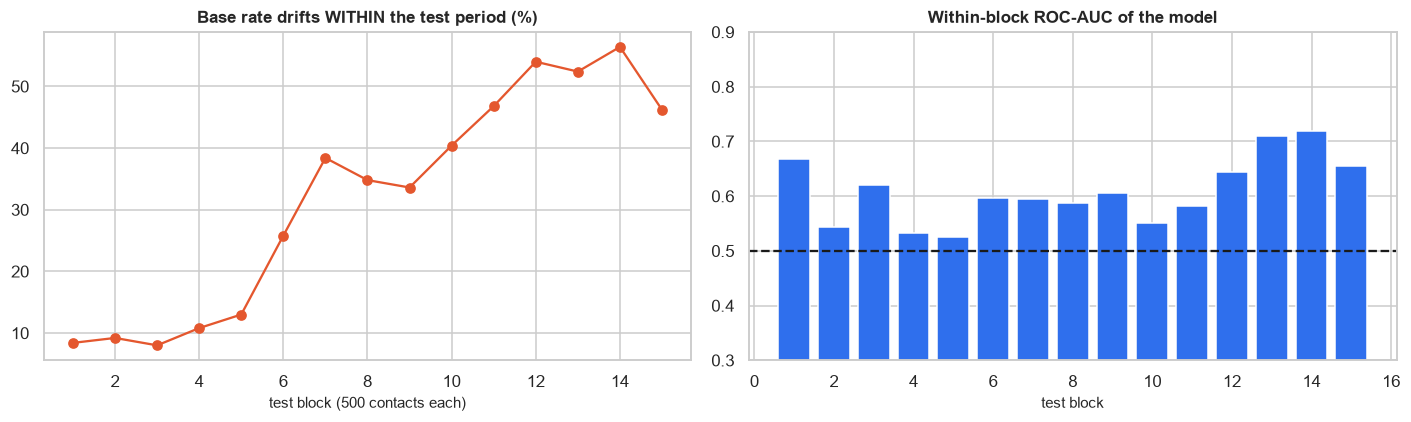

In [2]:
def valid_block(yb): return len(yb) >= BLOCK // 2 and 5 <= yb.sum() < len(yb)
def block_auc(s):
    return float(np.mean([roc_auc_score(y_test[a:a + BLOCK], s[a:a + BLOCK]) for a in range(0, len(y_test), BLOCK) if valid_block(y_test[a:a + BLOCK])]))

cut_cal = int(len(X_train) * 0.75)
fit_pipe = clone(best_pipe).fit(X_train.iloc[:cut_cal], y_train[:cut_cal])
raw_cal = fit_pipe.predict_proba(X_train.iloc[cut_cal:])[:, 1]
y_cal = y_train[cut_cal:]
s_fit75 = fit_pipe.predict_proba(X_test)[:, 1]
print(f"Trained on first 75% of training -> AUC on the NEXT training block: {roc_auc_score(y_cal, raw_cal):.3f} | on the test period: {roc_auc_score(y_test, s_fit75):.3f}")
print(f"Trained on ALL training rows      -> AUC on the test period       : {roc_auc_score(y_test, s_raw):.3f}")

rows = []
for i, a in enumerate(range(0, len(y_test), BLOCK)):
    yb, sb = y_test[a:a + BLOCK], s_raw[a:a + BLOCK]
    if not valid_block(yb):
        continue
    rows.append(dict(block=i + 1, base_rate=yb.mean(), auc=roc_auc_score(yb, sb), lift_at_budget=topk_metrics(yb, sb, CALL_BUDGET)[2]))
blocks = pd.DataFrame(rows).set_index("block")
display(blocks.round(3).T)
blocks.to_csv(TABLES_DIR / "test_blocks.csv")
print(f"Global test ROC-AUC {roc_auc_score(y_test, s_raw):.3f} | mean WITHIN-block ROC-AUC {blocks['auc'].mean():.3f} | mean within-block lift@{CALL_BUDGET:.0%} {blocks['lift_at_budget'].mean():.2f}x")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(blocks.index, blocks["base_rate"] * 100, marker="o", color=C_WARN); ax[0].set_title("Base rate drifts WITHIN the test period (%)"); ax[0].set_xlabel("test block (500 contacts each)")
ax[1].bar(blocks.index, blocks["auc"], color=C_MAIN); ax[1].axhline(0.5, color="k", ls="--"); ax[1].set_title("Within-block ROC-AUC of the model"); ax[1].set_xlabel("test block"); ax[1].set_ylim(0.3, 0.9)
plt.tight_layout(); save_fig("policy_within_block")

Global ROC-AUC aggregates both period-level macro variation and within-period client discrimination. Within-block AUC and lift isolate discrimination skill under shifting response rates.

Intercept shift applied per block: [0.1, 0.28, 0.28, 0.22, 0.74, 0.77, 1.18, 1.69, 1.89, 1.69, -0.88, 1.28, 0.8, 1.9, 2.59, 0.83]
Platt slope fitted on the last 25% of training: +0.420  (negative = it flips the ranking)


,roc_auc_global,roc_auc_within_block,brier,mean_predicted,distinct_values
version,,,,,
Raw scores (full-train model),0.6895,0.6089,0.2349,0.1845,7376
Rolling intercept (FINAL),0.7081,0.6089,0.2153,0.3215,7514
Platt on last 25% of train (free slope),0.6366,0.5551,0.2497,0.1352,7209
"Isotonic, train-era",0.6669,0.5637,0.2600,0.0911,47


Observed test base rate 0.324 | Brier of a constant base-rate predictor: 0.2190 (a useful model must beat this)


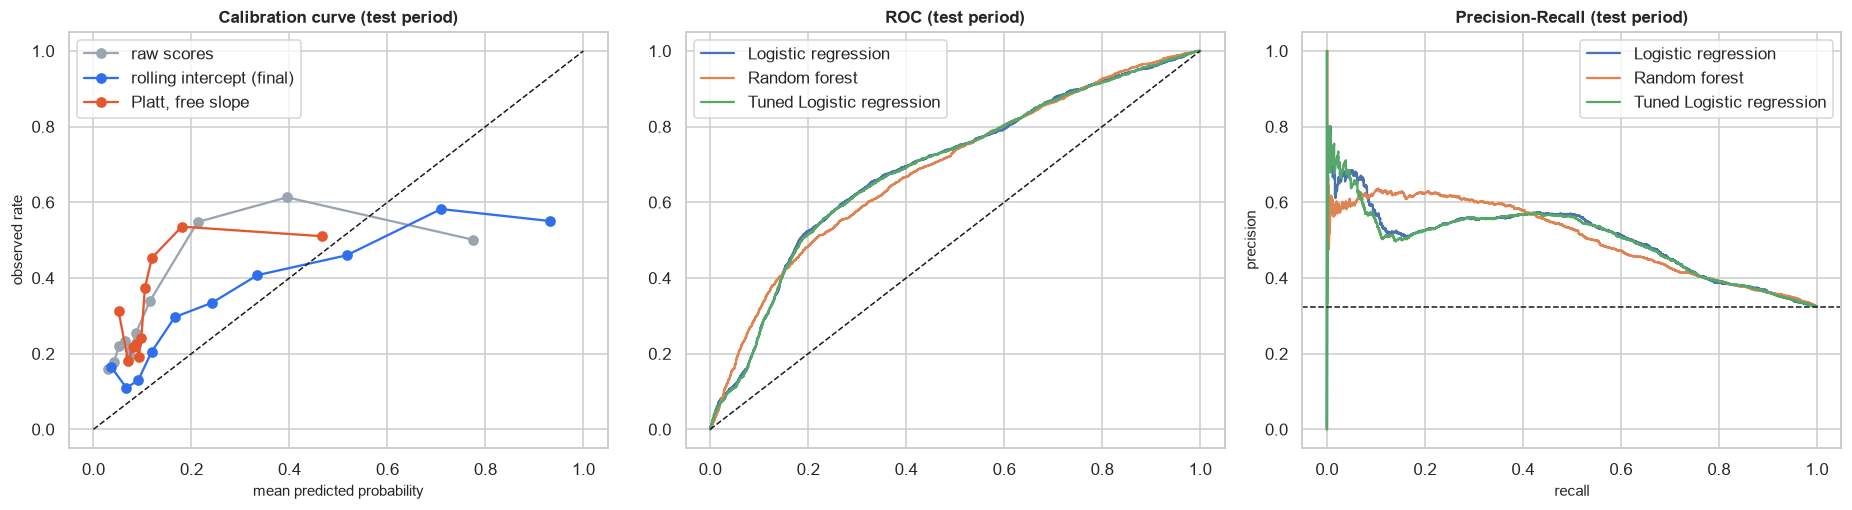

In [3]:
_clip = lambda p: np.clip(p, 1e-4, 1 - 1e-4)
def fit_intercept(p, rate):
    """Intercept b such that mean(expit(logit(p) + b)) equals the observed rate. Slope stays 1, so ranking is untouched."""
    z = logit(_clip(p)); rate = float(np.clip(rate, 0.01, 0.99))
    f = lambda b: expit(z + b).mean() - rate
    if f(-8) > 0: return -8.0
    if f(8) < 0: return 8.0
    return brentq(f, -8, 8)

s_cal = np.empty(len(X_test)); shifts = []
prev_p, prev_y = best_pipe.predict_proba(X_pilot)[:, 1], y_pilot
for a in range(0, len(X_test), BLOCK):
    b = fit_intercept(prev_p, prev_y.mean())
    s_cal[a:a + BLOCK] = expit(logit(_clip(s_raw[a:a + BLOCK])) + b); shifts.append(b)
    prev_p, prev_y = s_raw[a:a + BLOCK], y_test[a:a + BLOCK]
print("Intercept shift applied per block:", np.round(shifts, 2).tolist())

platt = LogisticRegression(C=1e6, max_iter=1000).fit(logit(_clip(raw_cal)).reshape(-1, 1), y_cal)
s_platt = platt.predict_proba(logit(_clip(s_fit75)).reshape(-1, 1))[:, 1]
s_iso = CalibratedClassifierCV(clone(best_pipe), method="isotonic", cv=3).fit(X_train, y_train).predict_proba(X_test)[:, 1]
print(f"Platt slope fitted on the last 25% of training: {platt.coef_[0][0]:+.3f}  (negative = it flips the ranking)")

const_brier = y_test.mean() * (1 - y_test.mean())
rows = []
for name, s in [("Raw scores (full-train model)", s_raw), ("Rolling intercept (FINAL)", s_cal), ("Platt on last 25% of train (free slope)", s_platt), ("Isotonic, train-era", s_iso)]:
    rows.append(dict(version=name, roc_auc_global=roc_auc_score(y_test, s), roc_auc_within_block=block_auc(s), brier=brier_score_loss(y_test, s),
                     mean_predicted=s.mean(), distinct_values=len(np.unique(np.round(s, 6)))))
display(pd.DataFrame(rows).set_index("version").round(4))
print(f"Observed test base rate {y_test.mean():.3f} | Brier of a constant base-rate predictor: {const_brier:.4f} (a useful model must beat this)")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for s, lab, c in [(s_raw, "raw scores", C_GREY), (s_cal, "rolling intercept (final)", C_MAIN), (s_platt, "Platt, free slope", C_WARN)]:
    fp, mp = calibration_curve(y_test, s, n_bins=10, strategy="quantile"); ax[0].plot(mp, fp, marker="o", label=lab, color=c)
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_xlabel("mean predicted probability"); ax[0].set_ylabel("observed rate"); ax[0].set_title("Calibration curve (test period)"); ax[0].legend()
show = [n for n in ["Logistic regression", "Random forest", TUNED_NAME] if n in test_scores]
for name in show:
    fpr, tpr, _ = roc_curve(y_test, test_scores[name]); ax[1].plot(fpr, tpr, label=name)
ax[1].plot([0, 1], [0, 1], "k--", lw=1); ax[1].set_title("ROC (test period)"); ax[1].legend()
for name in show:
    p_, r_, _ = precision_recall_curve(y_test, test_scores[name]); ax[2].plot(r_, p_, label=name)
ax[2].axhline(y_test.mean(), color="k", ls="--", lw=1); ax[2].set_title("Precision-Recall (test period)"); ax[2].set_xlabel("recall"); ax[2].set_ylabel("precision"); ax[2].legend()
plt.tight_layout(); save_fig("policy_calibration")

In [4]:
naive = np.empty(len(y_test)); prev_rate = float(y_pilot.mean())
for a in range(0, len(y_test), BLOCK):
    naive[a:a + BLOCK] = np.clip(prev_rate, 0.01, 0.99); prev_rate = y_test[a:a + BLOCK].mean()
print(f"Brier : naive rolling base rate (no model) {brier_score_loss(y_test, naive):.4f} | model + rolling intercept {brier_score_loss(y_test, s_cal):.4f} | constant oracle {const_brier:.4f}")
print(f"AUC   : naive rolling base rate {roc_auc_score(y_test, naive):.4f} (pure 'which period' signal) | model + rolling intercept {roc_auc_score(y_test, s_cal):.4f} | within-block model skill {block_auc(s_cal):.4f}")

Brier : naive rolling base rate (no model) 0.1928 | model + rolling intercept 0.2153 | constant oracle 0.2190
AUC   : naive rolling base rate 0.7128 (pure 'which period' signal) | model + rolling intercept 0.7081 | within-block model skill 0.6089


### Calibration Assessment
Rolling intercept adjustment updates the base rate to match recent observations while keeping ranking preserved. In contrast, static Platt and Isotonic calibration fitted on historical slices do not adapt to regime shifts, with isotonic collapsing distinct predictions into few steps. Rolling intercept adjustment preserves ranking while keeping probabilities aligned with recent rates.

---
## 3 · Gain and lift (ranking quality from the raw scores)

,clients,subscribers,response_rate,lift,cum_capture
decile,,,,,
1,774,388,0.501,1.547,0.155
2,774,474,0.612,1.890,0.344
3,773,424,0.549,1.693,0.513
4,774,263,0.340,1.049,0.618
5,773,197,0.255,0.786,0.696
6,774,149,0.193,0.594,0.756
7,774,180,0.233,0.718,0.828
8,773,171,0.221,0.683,0.896
9,774,138,0.178,0.550,0.951


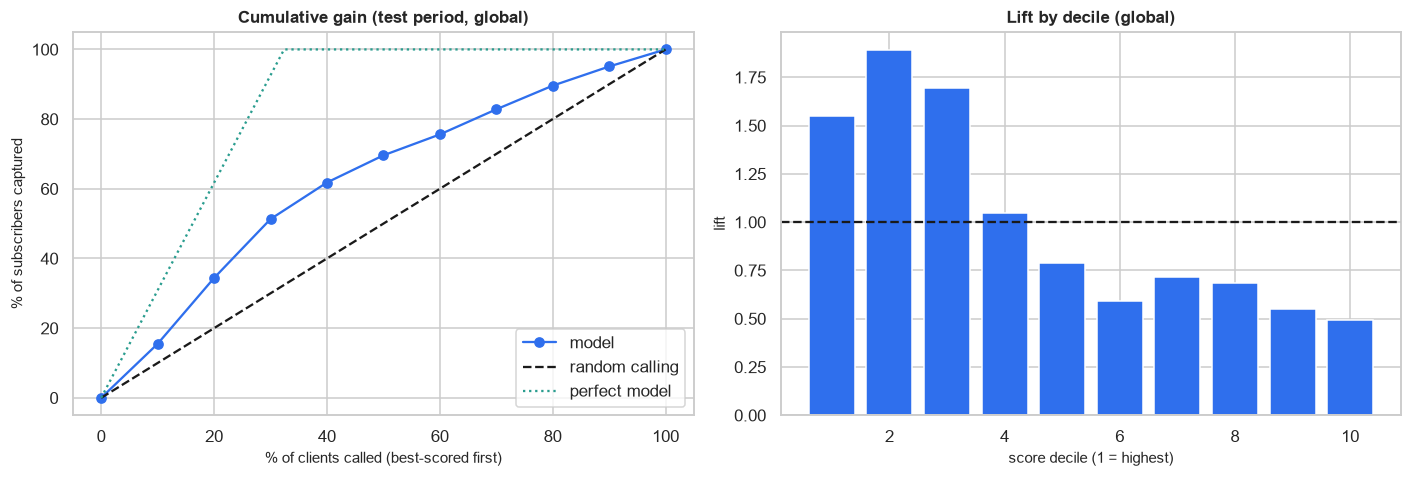

In [5]:
dt = decile_table(y_test, s_raw)
display(dt)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
x_ = np.r_[0, dt.index * 10]; g_ = np.r_[0, dt["cum_capture"].values * 100]
ax[0].plot(x_, g_, marker="o", color=C_MAIN, label="model"); ax[0].plot([0, 100], [0, 100], "k--", label="random calling")
ax[0].plot([0, y_test.mean() * 100, 100], [0, 100, 100], color=C_OK, ls=":", label="perfect model")
ax[0].set_xlabel("% of clients called (best-scored first)"); ax[0].set_ylabel("% of subscribers captured"); ax[0].set_title("Cumulative gain (test period, global)"); ax[0].legend()
ax[1].bar(dt.index, dt["lift"], color=C_MAIN); ax[1].axhline(1, color="k", ls="--"); ax[1].set_xlabel("score decile (1 = highest)"); ax[1].set_ylabel("lift"); ax[1].set_title("Lift by decile (global)")
plt.tight_layout(); save_fig("policy_gain_lift")

Lift is concentrated in top deciles, confirming ranking effectiveness for prioritization.

---
## 4 · Profit-maximising call policy
If a call costs *c* and a subscription is worth *v*, a call is worth making when `p * v > c`, so the break-even probability is **c / v**, valid only if *p* matches the **current** base rate (hence the rolling recalibration). For a **fixed call capacity** the natural policy is rank-based: each block, call the top `CALL_BUDGET` share by score. The fair baseline is **random calling at the same volume**.

,called_pct,precision,subscribers_captured_pct,profit_per_client
policy,,,,
Call nobody,0.000,NaN,0.000,0.000
Call everyone (no model),100.000,0.324,100.000,2.241
Model: top 20% of each block (fixed capacity),19.997,0.436,26.925,0.673
Random: 20% of clients (expected),20.000,0.324,20.000,0.448
Model: c/v=0.10 on raw scores (no recalibration),37.991,0.509,59.673,1.554
Model: c/v=0.10 on rolling-recalibrated probabilities,71.161,0.400,87.914,2.137
Oracle threshold 0.01 (NOT deployable),99.871,0.324,99.801,2.236


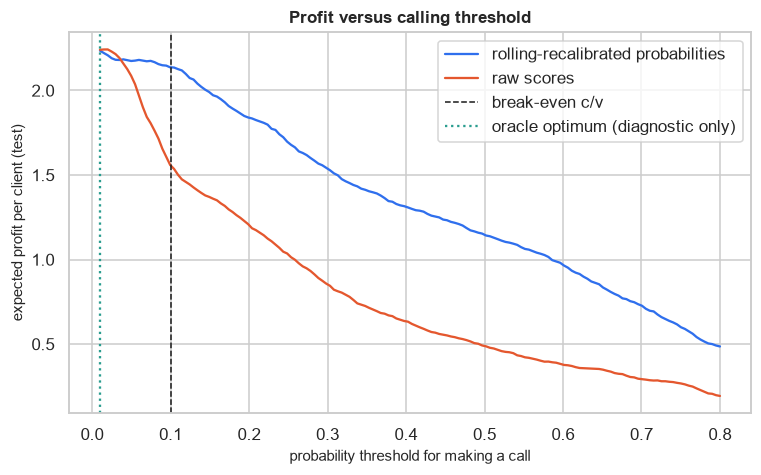

In [6]:
grid = np.linspace(0.01, 0.80, 160)
thr_theory = COST_PER_CALL / VALUE_PER_SUBSCRIPTION

def profit_per_client(y_true, score, thr):
    called = score >= thr
    return (VALUE_PER_SUBSCRIPTION * y_true[called].sum() - COST_PER_CALL * called.sum()) / len(y_true)
def policy_row(name, mask):
    n_called = int(mask.sum()); subs = int(y_test[mask].sum()) if n_called else 0
    return dict(policy=name, called_pct=100 * n_called / len(y_test), precision=subs / n_called if n_called else np.nan,
                subscribers_captured_pct=100 * subs / y_test.sum(), profit_per_client=(VALUE_PER_SUBSCRIPTION * subs - COST_PER_CALL * n_called) / len(y_test))
def per_block_topk_mask(score, frac):
    mask = np.zeros(len(score), bool)
    for a in range(0, len(score), BLOCK):
        idx = np.arange(a, min(a + BLOCK, len(score))); k = max(1, int(round(frac * len(idx))))
        mask[idx[rank_order(score[idx])[:k]]] = True
    return mask

budget_mask = per_block_topk_mask(s_raw, CALL_BUDGET)
test_profit = np.array([profit_per_client(y_test, s_cal, t) for t in grid])
thr_oracle = float(grid[test_profit.argmax()])
base = y_test.mean()
P_NOBODY, P_ALL = "Call nobody", "Call everyone (no model)"
P_BUDGET = f"Model: top {CALL_BUDGET:.0%} of each block (fixed capacity)"
P_RANDOM = f"Random: {CALL_BUDGET:.0%} of clients (expected)"
P_STALE = f"Model: c/v={thr_theory:.2f} on raw scores (no recalibration)"
P_FINAL = f"Model: c/v={thr_theory:.2f} on rolling-recalibrated probabilities"
P_ORACLE = f"Oracle threshold {thr_oracle:.2f} (NOT deployable)"
policies = pd.DataFrame([
    policy_row(P_NOBODY, np.zeros(len(y_test), bool)), policy_row(P_ALL, np.ones(len(y_test), bool)), policy_row(P_BUDGET, budget_mask),
    dict(policy=P_RANDOM, called_pct=100 * CALL_BUDGET, precision=base, subscribers_captured_pct=100 * CALL_BUDGET,
         profit_per_client=CALL_BUDGET * (VALUE_PER_SUBSCRIPTION * base - COST_PER_CALL)),
    policy_row(P_STALE, s_raw >= thr_theory), policy_row(P_FINAL, s_cal >= thr_theory), policy_row(P_ORACLE, s_cal >= thr_oracle),
]).set_index("policy").round(3)
display(policies)
policies.to_csv(TABLES_DIR / "policy_comparison.csv")
np.savez(ARTIFACTS_DIR / "policy_scores.npz", s_raw=s_raw, s_cal=s_cal, budget_mask=budget_mask)
json.dump({"P_BUDGET": P_BUDGET, "P_RANDOM": P_RANDOM, "P_ALL": P_ALL, "thr_theory": thr_theory}, open(ARTIFACTS_DIR / "policy_labels.json", "w"))

plt.figure(figsize=(8, 4.5))
plt.plot(grid, test_profit, label="rolling-recalibrated probabilities", color=C_MAIN)
plt.plot(grid, [profit_per_client(y_test, s_raw, t) for t in grid], label="raw scores", color=C_WARN)
plt.axvline(thr_theory, color="k", ls="--", lw=1, label="break-even c/v"); plt.axvline(thr_oracle, color=C_OK, ls=":", label="oracle optimum (diagnostic only)")
plt.xlabel("probability threshold for making a call"); plt.ylabel("expected profit per client (test)"); plt.title("Profit versus calling threshold"); plt.legend()
save_fig("policy_profit_curve")

### Sensitivity Analysis
Evaluating profitability and calling volume across varying subscription values and break-even thresholds.

In [7]:
rows = []
for v in [2, 3, 5, 10, 20]:
    thr = COST_PER_CALL / v; mask = s_cal >= thr
    n_called, subs = int(mask.sum()), int(y_test[mask].sum())
    rows.append(dict(value_per_subscription=v, break_even_prob=thr, called_pct=100 * mask.mean(), precision=subs / n_called if n_called else np.nan,
                     model_profit_per_client=(v * subs - COST_PER_CALL * n_called) / len(y_test), call_everyone_profit=v * y_test.mean() - COST_PER_CALL))
display(pd.DataFrame(rows).set_index("value_per_subscription").round(3))
print(f"Train base rate {y_train.mean():.3f} vs test base rate {y_test.mean():.3f}.")

,break_even_prob,called_pct,precision,model_profit_per_client,call_everyone_profit
value_per_subscription,,,,,
2,0.500,25.711,0.545,0.023,-0.352
3,0.333,34.540,0.517,0.191,-0.028
5,0.200,50.271,0.466,0.668,0.620
10,0.100,71.161,0.400,2.137,2.241
20,0.050,91.313,0.338,5.263,5.481


Train base rate 0.064 vs test base rate 0.324.


---
## 5 · Operating Points and Classification Metrics

Evaluating classification thresholds tuned on validation data (max F1, max F2, target recall, break-even $c/v$) against capacity-constrained policies.

,threshold,val_called_pct,test_called_pct,val_f1,test_precision,test_recall,test_f1,test_f2,calls_per_subscriber,test_profit_per_client
policy,,,,,,,,,,
Max F1 (validation),0.099,23.157,20.747,0.267,0.518,0.331,0.404,0.357,1.931,0.867
"Max F2, recall-weighted (validation)",0.073,49.047,27.637,0.240,0.506,0.431,0.465,0.444,1.978,1.121
Recall >= 70% (validation),0.058,56.515,35.315,0.230,0.485,0.529,0.506,0.519,2.062,1.360
Break-even c/v = 0.10,0.100,21.712,20.450,0.266,0.520,0.328,0.402,0.354,1.925,0.858
Static top-20% cut-off (validation),0.102,20.000,20.075,0.263,0.522,0.323,0.400,0.350,1.915,0.848
Rank-based top-20% of each block,NaN,20.000,19.997,NaN,0.403,0.249,0.307,0.269,2.483,0.605


Test base rate 32.407% | validation base rate 11.075%. A big gap between val_called_pct and test_called_pct means the cut-off did not transfer across periods.


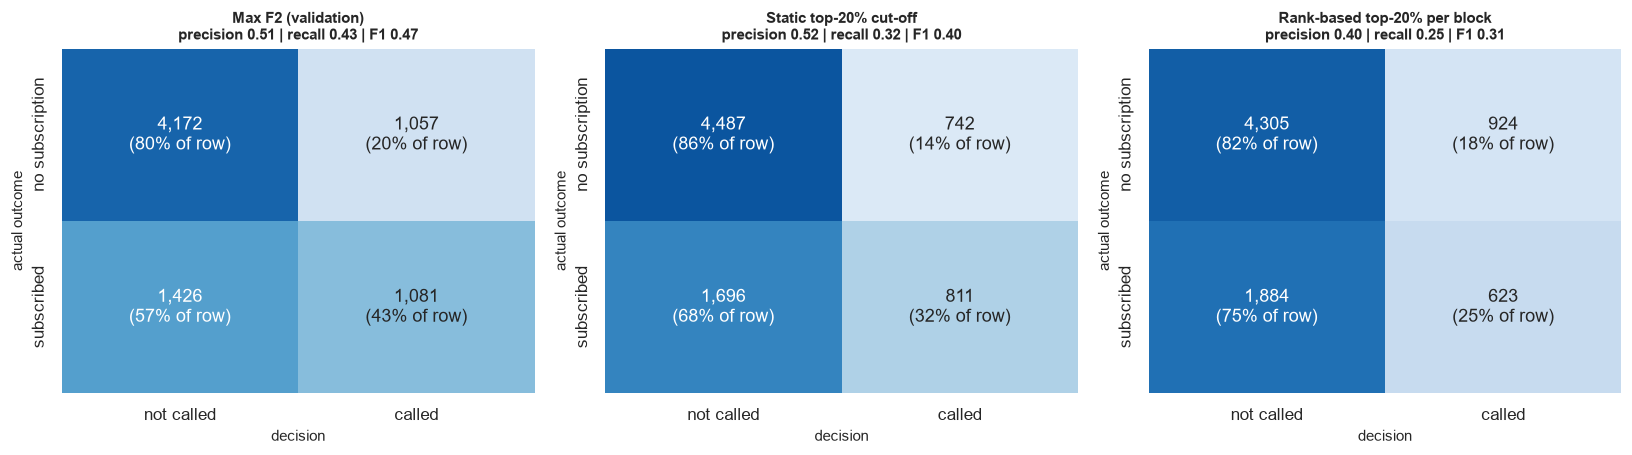

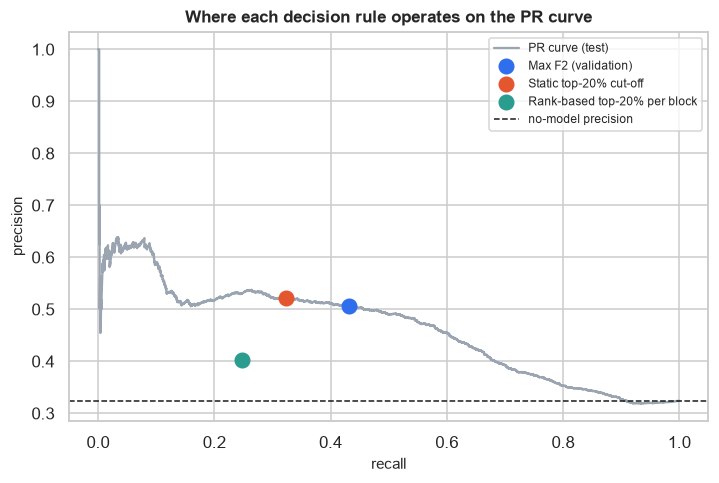

Best test F2 among the rules above: 'Recall >= 70% (validation)' -> 2.1 calls per subscriber won.


In [8]:
op_cut = int(len(X_train) * 0.75)
op_model = clone(best_pipe).fit(X_train.iloc[:op_cut], y_train[:op_cut])
op_vs, op_vy = op_model.predict_proba(X_train.iloc[op_cut:])[:, 1], y_train[op_cut:]
op_ts = op_model.predict_proba(X_test)[:, 1]

def op_metrics(y_true, called):
    tp = int((called & (y_true == 1)).sum()); fp = int((called & (y_true == 0)).sum()); fn = int((~called & (y_true == 1)).sum()); tn = int((~called & (y_true == 0)).sum())
    prec, rec = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return dict(called_pct=100 * called.mean(), precision=prec, recall=rec, f1=2 * prec * rec / max(prec + rec, 1e-12), f2=5 * prec * rec / max(4 * prec + rec, 1e-12),
                calls_per_subscriber=(tp + fp) / max(tp, 1), tp=tp, fp=fp, fn=fn, tn=tn)

_cand = np.unique(np.quantile(op_vs, np.linspace(0.40, 0.995, 240)))
_v = pd.DataFrame([op_metrics(op_vy, op_vs >= t) for t in _cand], index=_cand)
op_thr = {
    "Max F1 (validation)": float(_v["f1"].idxmax()),
    "Max F2, recall-weighted (validation)": float(_v["f2"].idxmax()),
    "Recall >= 70% (validation)": float(_v.index[_v["recall"] >= 0.70].max()) if (_v["recall"] >= 0.70).any() else float(_v.index.min()),
    f"Break-even c/v = {thr_theory:.2f}": thr_theory,
    f"Static top-{CALL_BUDGET:.0%} cut-off (validation)": float(np.quantile(op_vs, 1 - CALL_BUDGET)),
}
rows = []
for name, t in op_thr.items():
    mv, mt = op_metrics(op_vy, op_vs >= t), op_metrics(y_test, op_ts >= t)
    rows.append(dict(policy=name, threshold=t, val_called_pct=mv["called_pct"], test_called_pct=mt["called_pct"], val_f1=mv["f1"], test_precision=mt["precision"],
                     test_recall=mt["recall"], test_f1=mt["f1"], test_f2=mt["f2"], calls_per_subscriber=mt["calls_per_subscriber"],
                     test_profit_per_client=(VALUE_PER_SUBSCRIPTION * mt["tp"] - COST_PER_CALL * (mt["tp"] + mt["fp"])) / len(y_test)))
_mt = op_metrics(y_test, per_block_topk_mask(op_ts, CALL_BUDGET))
rows.append(dict(policy=f"Rank-based top-{CALL_BUDGET:.0%} of each block", threshold=np.nan, val_called_pct=100 * CALL_BUDGET, test_called_pct=_mt["called_pct"], val_f1=np.nan,
                 test_precision=_mt["precision"], test_recall=_mt["recall"], test_f1=_mt["f1"], test_f2=_mt["f2"], calls_per_subscriber=_mt["calls_per_subscriber"],
                 test_profit_per_client=(VALUE_PER_SUBSCRIPTION * _mt["tp"] - COST_PER_CALL * (_mt["tp"] + _mt["fp"])) / len(y_test)))
op_table = pd.DataFrame(rows).set_index("policy")
display(op_table.round(3))
op_table.to_csv(TABLES_DIR / "operating_points.csv")
print(f"Test base rate {y_test.mean():.3%} | validation base rate {op_vy.mean():.3%}. A big gap between val_called_pct and test_called_pct means the cut-off did not transfer across periods.")

show_rules = {"Max F2 (validation)": op_ts >= op_thr["Max F2, recall-weighted (validation)"],
              f"Static top-{CALL_BUDGET:.0%} cut-off": op_ts >= op_thr[f"Static top-{CALL_BUDGET:.0%} cut-off (validation)"],
              f"Rank-based top-{CALL_BUDGET:.0%} per block": per_block_topk_mask(op_ts, CALL_BUDGET)}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for a_, (name, called) in zip(ax, show_rules.items()):
    cm = confusion_matrix(y_test, called.astype(int), labels=[0, 1]); pct = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(pct, annot=np.array([[f"{cm[i, j]:,}\n({pct[i, j]:.0%} of row)" for j in range(2)] for i in range(2)]), fmt="", cmap="Blues", cbar=False, ax=a_, vmin=0, vmax=1,
                xticklabels=["not called", "called"], yticklabels=["no subscription", "subscribed"])
    m_ = op_metrics(y_test, called); a_.set_title(f"{name}\nprecision {m_['precision']:.2f} | recall {m_['recall']:.2f} | F1 {m_['f1']:.2f}", fontsize=10); a_.set_xlabel("decision"); a_.set_ylabel("actual outcome")
plt.tight_layout(); save_fig("policy_confusion_matrices")

p_, r_, _ = precision_recall_curve(y_test, op_ts)
plt.figure(figsize=(7.5, 4.6)); plt.plot(r_, p_, color=C_GREY, label="PR curve (test)")
for (name, called), c in zip(show_rules.items(), [C_MAIN, C_WARN, C_OK]):
    m_ = op_metrics(y_test, called); plt.scatter(m_["recall"], m_["precision"], s=90, color=c, label=name, zorder=3)
plt.axhline(y_test.mean(), color="k", ls="--", lw=1, label="no-model precision"); plt.xlabel("recall"); plt.ylabel("precision")
plt.title("Where each decision rule operates on the PR curve"); plt.legend(fontsize=8)
save_fig("policy_operating_points")
_best = op_table["test_f2"].idxmax()
print(f"Best test F2 among the rules above: '{_best}' -> {op_table.loc[_best, 'calls_per_subscriber']:.1f} calls per subscriber won.")

### Policy Comparison Takeaways
Fixed probability thresholds produce unstable call volumes when underlying base rates shift. A rank-based capacity policy maintains predictable operations and steady efficiency across changing campaign conditions.